# NGC 4654 maximum SFR-excess contrast

Use the 7000-run Paper II SF selection, equal-galaxy pre-peak rSFMS and width \(W\). Each selected SF spaxel contributes its own normalized residual \(E=(\log\Sigma_{\rm SFR}-\log\Sigma_{\rm SFR,ref})/W\).

A line through the photometric centre divides the observed SF footprint into two halves. Its normal points at projected PA \(\theta\), east of north, toward the positive half. At each trial angle, take the difference between the arithmetic means of \(E\) in the two halves, giving each spaxel equal weight within its half. The calculation uses the full selected SF footprint.

$$
H_\pm(\theta)=\{i:\ \pm\cos(\phi_i-\theta)>0\},\qquad
D(\theta)=\overline E_+-\overline E_-,\qquad
\theta_{\max}=\arg\max_\theta D(\theta).
$$

The maximizing direction describes the observed contrast. \(D_{\max}\) is in units of \(W\). The analysis reports a point estimate.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    gas_arrays['LOGSFR_SURFACE_DENSITY_HII'] += delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


In [3]:
# Load the pre-peak reference and the close-to-peak comparison sample.
def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        if not geometry_by_galaxy.loc[list(components), 'stage_code'].isin((1, 2)).any():
            continue
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            if component.stage_code not in (1, 2):
                continue
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths

sf_x_parts, sf_y_parts, sf_group_parts, sf_error_parts = [], [], [], []
sf_radius_parts = []
inventory_rows, count_rows = [], []
ngc4654_sf_geometry = None
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    assert not np.any(sf & ~balmer), f'{gal}: SF overlaps Balmer ND'
    group_id = len(count_rows)
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    # Preserve the selected SF order when computing elliptical radii.
    sf_wcs = WCS(mass_hdr).celestial
    pixel_y, pixel_x = np.nonzero(sf)
    ra, dec = sf_wcs.pixel_to_world_values(pixel_x, pixel_y)
    east, north = tangent_offsets_arcsec(ra, dec, component.center_ra_deg, component.center_dec_deg)
    pa = np.deg2rad(float(component.pa_deg_east_of_north))
    major = east * np.sin(pa) + north * np.cos(pa)
    minor = east * np.cos(pa) - north * np.sin(pa)
    radius_re = np.hypot(major / component.a_re_arcsec, minor / component.b_re_arcsec)
    if not np.isfinite(radius_re).all():
        raise ValueError(f'{gal}: nonfinite elliptical radii among selected SF spaxels')
    sf_radius_parts.append(radius_re)
    if gal == 'NGC4654':
        ngc4654_sf_mask = sf.copy()
        ngc4654_wcs = sf_wcs
        ngc4654_sf_geometry = pd.DataFrame(dict(east=east, north=north))
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                           usable=int(valid.sum()), SF=int(sf.sum())))

if not count_rows:
    raise RuntimeError('No complete Paper II product sets found for the pre-peak or close-to-peak stages')
inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
sf_x, sf_y, sf_group = (np.concatenate(parts) for parts in (sf_x_parts, sf_y_parts, sf_group_parts))
sf_radius_re = np.concatenate(sf_radius_parts)
assert sf_x.size == sf_y.size == sf_group.size == sf_radius_re.size == counts.SF.sum()
display(inventory[['galaxy', 'product_id', 'stage', 'inclination', 'status']])
display(counts)

,galaxy,product_id,stage,inclination,status
0,NGC4189,NGC4189,1,42.0,included
1,NGC4192,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
2,NGC4222,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
3,NGC4254,NGC4254,1,39.0,included
4,NGC4294,NGC4294,1,74.0,included
5,NGC4298,NGC4298,2,52.0,included
6,NGC4302,NGC4302,2,90.0,excluded: inclination >=80 or unavailable
7,NGC4321,NGC4321,1,32.0,included
8,NGC4330,NGC4330,2,90.0,excluded: inclination >=80 or unavailable
9,NGC4351,NGC4351,1,48.0,included


,galaxy,stage,inclination,usable,SF
0,NGC4189,1,42.0,134346,88582
1,NGC4254,1,39.0,615883,453580
2,NGC4294,1,74.0,125185,66537
3,NGC4298,2,52.0,255189,140421
4,NGC4321,1,32.0,808599,382821
5,NGC4351,1,48.0,98128,29767
6,NGC4383,1,56.0,62174,15627
7,NGC4424,2,61.0,149185,8627
8,NGC4501,2,65.0,653467,252942
9,NGC4535,1,48.0,459337,161648


In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

sf_stage = counts.stage.to_numpy(int)[sf_group]
assert (sf_stage == 1).any(), 'No pre-peak SF reference products'
pre=sf_stage==1
pre_peak_fit=equal_galaxy_ols(sf_x[pre],sf_y[pre],sf_group[pre])

assert counts.inclination.lt(INCLINATION_MAX).all()
excess_meta = counts.reset_index(drop=True)
target = excess_meta.loc[excess_meta.galaxy.eq('NGC4654')]
if len(target) != 1 or int(target.iloc[0].SF) == 0:
    raise ValueError('NGC4654: not available with SF spaxels after the global cuts; inspect inventory')
assert int(target.iloc[0].stage) == 2, 'NGC4654: unexpected catalogue stage'
excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width

display(excess_width_by_galaxy)
print(f'Pre-peak equal-galaxy reference: y={pre_peak_fit["slope"]:.6f}x{pre_peak_fit["intercept"]:+.6f}; W={excess_width:.6f} dex')

,galaxy,N_width,width_dex,fraction_clipped_to_zero
0,NGC4189,88582,0.359797,0.027974
1,NGC4254,453580,0.447343,0.028438
2,NGC4294,66537,0.357248,0.014188
3,NGC4321,382821,0.389444,0.029442
4,NGC4351,29767,0.366184,0.017402
5,NGC4383,15627,0.444388,0.018878
6,NGC4535,161648,0.464960,0.016307
7,NGC4567,87590,0.335900,0.039034
8,NGC4568,114364,0.358164,0.042076


Pre-peak equal-galaxy reference: y=0.748260x-7.992286; W=0.391492 dex


## Spaxel-level excess map

Each selected SF spaxel is shown at its native pixel with its own excess value.

In [5]:
ngc4654_group = excess_meta.index[excess_meta.galaxy.eq('NGC4654')].item()
ngc4654_excess = excess_values[sf_group == ngc4654_group]
if ngc4654_sf_geometry is None or len(ngc4654_sf_geometry) != ngc4654_excess.size:
    raise ValueError('Rerun the input and calibration cells to align the NGC4654 geometry and SF residuals.')
ngc4654_map = ngc4654_sf_geometry.assign(excess=ngc4654_excess)
spaxel_map = np.full(ngc4654_sf_mask.shape, np.nan)
spaxel_map[ngc4654_sf_mask] = ngc4654_excess

# A pixel exactly at the centre has no azimuth.
has_azimuth = np.hypot(ngc4654_map.east, ngc4654_map.north) > 0
cut_spaxels = ngc4654_map.loc[has_azimuth].copy()
cut_spaxels['phi_deg'] = np.degrees(
    np.arctan2(cut_spaxels.east, cut_spaxels.north)) % 360
print(f'{len(cut_spaxels):,} selected SF spaxels with a defined sky azimuth')


325,678 selected SF spaxels with a defined sky azimuth


## Search every distinct half-map cut

Spaxel membership changes at \(\theta=\phi_i\pm90^\circ\). Evaluate the open intervals between successive crossings, including the interval that wraps across north, and require at least one spaxel in each half. Report all intervals tied for the maximum within numerical tolerance and the midpoint of the widest one as the representative PA. The interval bounds describe the partition. A spaxel exactly at the centre is shown on the map and contributes to the whole-galaxy fraction, but has no half assignment.

In [6]:
def scan_half_cuts(spaxels):
    """Compute spaxel counts and means on all open angular intervals."""
    if spaxels.empty:
        raise ValueError('No selected SF spaxels with a defined sky azimuth.')
    ordered = spaxels.sort_values('phi_deg')
    phi = ordered.phi_deg.to_numpy()
    values = ordered.excess.to_numpy()

    # Merge coincident crossing angles up to floating-point precision in sky PA.
    boundaries = np.unique(np.round((phi + 90) % 180, 10) % 180)
    boundaries = np.r_[boundaries, boundaries + 180]
    right_edges = np.r_[boundaries[1:], boundaries[0] + 360]
    midpoints = ((boundaries + right_edges) / 2) % 360
    half_start = (midpoints - 90) % 360

    # A cumulative sum on the doubled angular range handles windows crossing north.
    angles = np.r_[phi, phi + 360]
    cumulative = np.r_[0.0, np.cumsum(np.tile(values, 2))]
    start = np.searchsorted(angles, half_start, side='right')
    stop = np.searchsorted(angles, half_start + 180, side='left')
    n_plus = stop - start
    n_minus = len(phi) - n_plus
    sum_plus = cumulative[stop] - cumulative[start]
    mean_plus = np.divide(sum_plus, n_plus, out=np.full(len(start), np.nan), where=n_plus > 0)
    mean_minus = np.divide(values.sum() - sum_plus, n_minus,
                           out=np.full(len(start), np.nan), where=n_minus > 0)

    return pd.DataFrame({
        'start_deg': boundaries, 'end_deg': right_edges, 'theta_deg': midpoints,
        'width_deg': right_edges - boundaries, 'D_W': mean_plus - mean_minus,
        'N_plus': n_plus, 'N_minus': n_minus,
        'mean_E_plus': mean_plus, 'mean_E_minus': mean_minus,
    })


cuts = scan_half_cuts(cut_spaxels)
eligible_cuts = cuts.D_W.notna()
if not eligible_cuts.any():
    raise ValueError('No angular interval contains selected SF spaxels in both halves.')
peak = cuts.loc[eligible_cuts, 'D_W'].max()
max_intervals = cuts.loc[np.isclose(cuts.D_W, peak, rtol=0, atol=1e-12)].sort_values(
    ['width_deg', 'start_deg'], ascending=[False, True])
best = max_intervals.iloc[0]
theta_max = float(best.theta_deg)
D_max = float(best.D_W)

# Use direct signed projections to verify and retain the maximizing partition.
theta = np.deg2rad(theta_max)
projection = cut_spaxels.east * np.sin(theta) + cut_spaxels.north * np.cos(theta)
selected_plus = projection > 0
selected_minus = projection < 0
half_values = {
    'Positive half': cut_spaxels.loc[selected_plus, 'excess'].to_numpy(),
    'Negative half': cut_spaxels.loc[selected_minus, 'excess'].to_numpy(),
}
for label, count, mean in (
    ('Positive half', best.N_plus, best.mean_E_plus),
    ('Negative half', best.N_minus, best.mean_E_minus),
):
    values = half_values[label]
    assert values.size == count
    np.testing.assert_allclose(values.mean(), mean, atol=1e-12, rtol=0)

print(f'theta_max = {theta_max:.4f} deg east of north')
print(f'D_max = {D_max:.6f} W ({D_max * excess_width:.6f} dex residual contrast)')
print(f'{eligible_cuts.sum():,} of {len(cuts):,} angular intervals have spaxels in both halves.')
display(max_intervals[['start_deg', 'end_deg', 'theta_deg', 'width_deg', 'D_W']])
display(pd.DataFrame({
    'N_SF': {label: values.size for label, values in half_values.items()},
    'Mean E': {label: values.mean() for label, values in half_values.items()},
}))


theta_max = 318.7335 deg east of north
D_max = 0.456263 W (0.178623 dex residual contrast)
651,356 of 651,356 angular intervals have spaxels in both halves.


,start_deg,end_deg,theta_deg,width_deg,D_W
594818,318.733013,318.733967,318.73349,0.000954,0.456263


,N_SF,Mean E
Positive half,165102,-0.028779
Negative half,160576,-0.485041


## Spaxel map and angular contrast

The dashed line marks the maximizing cut, and the arrow points toward the positive half. Gaps in the contrast curve indicate cuts with an empty half.

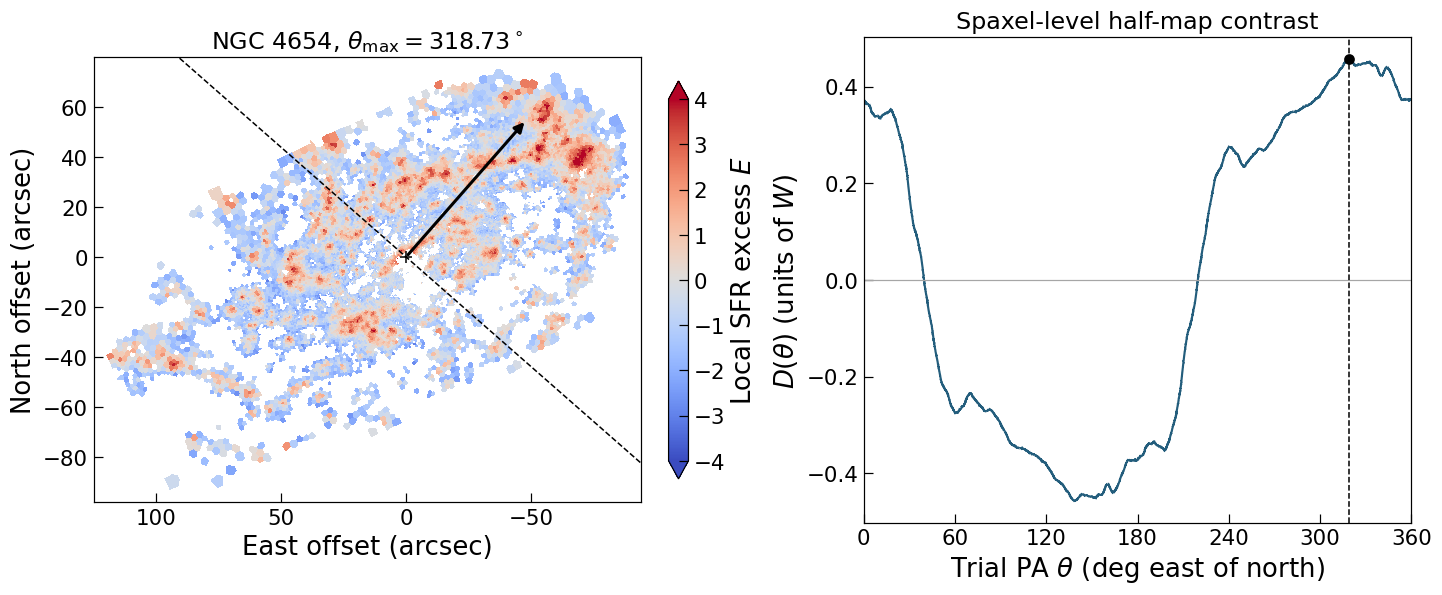

In [7]:
# Convert the native pixel corners to the same tangent plane used by the cut.
ny, nx = spaxel_map.shape
pixel_x, pixel_y = np.meshgrid(np.arange(nx + 1) - 0.5, np.arange(ny + 1) - 0.5)
ra, dec = ngc4654_wcs.pixel_to_world_values(pixel_x, pixel_y)
centre = geometry_by_galaxy.loc['NGC4654']
east, north = tangent_offsets_arcsec(ra, dec, centre.center_ra_deg, centre.center_dec_deg)

fig, (ax_map, ax_curve) = plt.subplots(1, 2, figsize=(13, 5.3), layout='constrained')
mesh = ax_map.pcolormesh(east, north, spaxel_map, cmap='coolwarm', vmin=-4, vmax=4,
                         shading='flat', rasterized=True)
fig.colorbar(mesh, ax=ax_map, label=r'Local SFR excess $E$', extend='both', shrink=0.82)

theta = np.deg2rad(theta_max)
extent = np.hypot(cut_spaxels.east, cut_spaxels.north).max()
along_line = np.array([-2, 2]) * extent
ax_map.plot(along_line * np.cos(theta), -along_line * np.sin(theta),
            'k--', lw=1, label='Dividing line')
ax_map.annotate('', xy=0.55 * extent * np.array([np.sin(theta), np.cos(theta)]),
                xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', lw=2, color='black'))
ax_map.plot(0, 0, 'k+', ms=8)
yy, xx = np.nonzero(ngc4654_sf_mask)
margin = 5
ax_map.set(aspect='equal', xlim=(east[yy, xx].max() + margin, east[yy, xx].min() - margin),
           ylim=(north[yy, xx].min() - margin, north[yy, xx].max() + margin),
           xlabel='East offset (arcsec)', ylabel='North offset (arcsec)',
           title=rf'NGC 4654, $\theta_{{\max}}={theta_max:.2f}^\circ$')

curve = cuts.D_W.where(eligible_cuts).to_numpy()
plot_edges = np.r_[0, cuts.start_deg, 360]
plot_values = np.r_[curve[-1], curve]
ax_curve.stairs(plot_values, plot_edges, baseline=None, color='#235d7c', linewidth=1.4)
ax_curve.axhline(0, color='0.65', linewidth=0.8)
ax_curve.axvline(theta_max, color='black', linestyle='--', linewidth=1)
ax_curve.scatter(theta_max, D_max, color='black', zorder=3)
ax_curve.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
             xlabel=r'Trial PA $\theta$ (deg east of north)', ylabel=r'$D(\theta)$ (units of $W$)',
             title='Spaxel-level half-map contrast')
plt.show()

## Selected SF fraction in the two halves

As in Paper II cell 44, each curve shows the fraction of selected SF spaxels with \(E>t\). The pre-peak and close-to-peak curves weight galaxies equally, and the band spans the 16th–84th percentiles of the individual pre-peak galaxy fractions. The close-to-peak mean includes NGC 4654.

Each half uses its own SF-spaxel denominator, with membership determined by each spaxel's position relative to the maximizing cut. Zero fractions are omitted on the log axis and retained in the counts table.

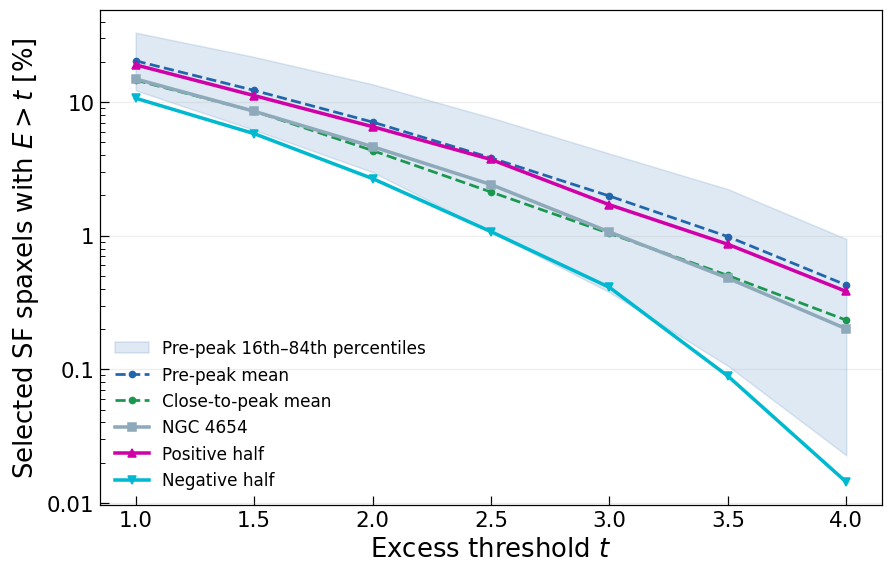

E threshold,Selected SF total,1.0,1.5,2.0,2.5,3.0,3.5,4.0
NGC4654,325678,48496,27774,15100,7858,3471,1566,654
Positive half,165102,31344,18456,10804,6137,2812,1423,631
Negative half,160576,17152,9318,4296,1721,659,143,23


In [8]:
from matplotlib.ticker import StrMethodFormatter

GALAXY = 'NGC4654'
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}
GALAXY_COLORS = {}
for palette_line in (PROJECT_ROOT / 'MAUVE_galaxy_colors.dat').read_text().splitlines():
    if not palette_line.strip() or palette_line.lstrip().startswith('#'):
        continue
    fields = palette_line.split()
    if fields[1] != 'TOTAL_ASSEMBLED':
        GALAXY_COLORS[fields[1]] = fields[3]

excess_thresholds = np.arange(1, 4.5, 0.5)

def tail_counts(values):
    # Strict inequality and the same thresholds as the Paper II curves.
    return np.count_nonzero(values[:, None] > excess_thresholds, axis=0)

galaxy_tails = {
    record.galaxy: tail_counts(excess_values[sf_group == group_id]) / record.SF
    for group_id, record in excess_meta.iterrows() if record.SF > 0
}
stage_tails = {
    stage: np.stack([galaxy_tails[gal] for gal in excess_meta.loc[
        excess_meta.stage.eq(stage) & excess_meta.SF.gt(0), 'galaxy']])
    for stage in (1, 2)
}
stage_means = {stage: tails.mean(axis=0) for stage, tails in stage_tails.items()}
pre_bounds = np.quantile(stage_tails[1], [0.16, 0.84], axis=0)

region_values = {GALAXY: ngc4654_excess, **half_values}
region_counts = {label: tail_counts(values) for label, values in region_values.items()}
region_fractions = {
    label: region_counts[label] / values.size for label, values in region_values.items()
}
assert np.allclose(region_fractions[GALAXY], galaxy_tails[GALAXY])

fig_fraction, ax = plt.subplots(figsize=(8.0, 5.1), layout='constrained')
ax.fill_between(excess_thresholds, 100 * pre_bounds[0], 100 * pre_bounds[1],
    where=pre_bounds[0] > 0, color=STAGE_COLORS[1], alpha=0.14,
    label='Pre-peak 16th–84th percentiles')
for stage in (1, 2):
    ax.plot(excess_thresholds, 100 * stage_means[stage], 'o--', lw=1.8, ms=4,
        color=STAGE_COLORS[stage], label=f'{STAGE_LABELS[stage]} mean')
region_colors = {
    GALAXY: GALAXY_COLORS[GALAXY],
    'Positive half': '#d000a8',
    'Negative half': '#00b9d0',
}
for (label, fraction), marker in zip(region_fractions.items(), ('s', '^', 'v')):
    ax.plot(excess_thresholds, 100 * fraction, marker=marker, ms=5, lw=2.3,
        color=region_colors[label], label='NGC 4654' if label == GALAXY else label)
ax.set(xticks=excess_thresholds, xlabel=r'Excess threshold $t$',
    ylabel='Selected SF spaxels with $E>t$ [%]')
ax.set_yscale('log', nonpositive='mask')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
ax.grid(axis='y', alpha=0.22)
ax.legend(loc='lower left', frameon=False, fontsize=11)
plt.show()

support = pd.DataFrame(region_counts, index=pd.Index(excess_thresholds, name='E threshold')).T
support.insert(0, 'Selected SF total', [values.size for values in region_values.values()])
display(support)


## Radius-weighted contrast within \(1.6R_e\)

Use selected SF spaxels with \(0\leq r/R_e\leq1.6\), where \(r/R_e\) is the elliptical radius from the Paper II photometric geometry for each galaxy. The pre-peak rSFMS and \(W\) above set the excess scale in both analyses.

For the maximizing cut, the mean in each half is \(\overline E_w=\sum_i (r_i/R_e)E_i\,/\,\sum_i (r_i/R_e)\). The scan maximizes the positive-half weighted mean minus the negative-half weighted mean. The map shows individual spaxel excesses. All fraction curves use the same aperture and count spaxels equally. The stage means and the pre-peak band give equal weight to galaxies.

In [9]:
RADIAL_LIMIT_RE = 1.6
within_radius = (sf_radius_re >= 0) & (sf_radius_re <= RADIAL_LIMIT_RE)
ngc4654_r_re = sf_radius_re[sf_group == ngc4654_group]
ngc4654_within_radius = within_radius[sf_group == ngc4654_group]
radial_sf_mask = ngc4654_sf_mask.copy()
radial_sf_mask[ngc4654_sf_mask] = ngc4654_within_radius
radial_spaxel_map = np.where(radial_sf_mask, spaxel_map, np.nan)

radial_spaxels = cut_spaxels.assign(r_re=ngc4654_r_re[cut_spaxels.index])
radial_spaxels = radial_spaxels.loc[radial_spaxels.r_re.between(0, RADIAL_LIMIT_RE)]
radial_weights = radial_spaxels.r_re.to_numpy()

# For either half, mean(w * E) / mean(w) equals sum(w * E) / sum(w).
radial_cuts = scan_half_cuts(radial_spaxels.assign(excess=radial_weights * radial_spaxels.excess))
weight_cuts = scan_half_cuts(radial_spaxels.assign(excess=radial_weights))
mean_columns = ['mean_E_plus', 'mean_E_minus']
radial_cuts[mean_columns] = radial_cuts[mean_columns].div(
    weight_cuts[mean_columns].where(weight_cuts[mean_columns] > 0))
radial_cuts['D_W'] = radial_cuts.mean_E_plus - radial_cuts.mean_E_minus
radial_eligible = radial_cuts.D_W.notna()
if not radial_eligible.any():
    raise ValueError('No cut has positive total radius weight in both halves.')
radial_peak = radial_cuts.loc[radial_eligible, 'D_W'].max()
radial_best_intervals = radial_cuts.loc[
    np.isclose(radial_cuts.D_W, radial_peak, rtol=0, atol=1e-12)
].sort_values(['width_deg', 'start_deg'], ascending=[False, True])
radial_best = radial_best_intervals.iloc[0]
radial_theta = float(radial_best.theta_deg)
radial_contrast = float(radial_best.D_W)

radial_angle = np.deg2rad(radial_theta)
radial_projection = radial_spaxels.east * np.sin(radial_angle) + radial_spaxels.north * np.cos(radial_angle)
radial_half_values = {}
radial_half_rows = []
for label, take, count, mean in (
    ('Positive half', radial_projection > 0, radial_best.N_plus, radial_best.mean_E_plus),
    ('Negative half', radial_projection < 0, radial_best.N_minus, radial_best.mean_E_minus),
):
    values = radial_spaxels.loc[take, 'excess'].to_numpy()
    weights = radial_spaxels.loc[take, 'r_re'].to_numpy()
    assert values.size == count
    direct_mean = np.average(values, weights=weights)
    np.testing.assert_allclose(direct_mean, mean, atol=1e-12, rtol=0)
    radial_half_values[label] = values
    radial_half_rows.append({'Half': label, 'N_SF': values.size,
                             'Sum of weights': weights.sum(), 'Weighted mean E': direct_mean})

print(f'{radial_sf_mask.sum():,} selected NGC 4654 SF spaxels within {RADIAL_LIMIT_RE:g} Re')
print(f'Radius-weighted theta_max = {radial_theta:.4f} deg east of north')
print(f'Radius-weighted D_max = {radial_contrast:.6f} W ({radial_contrast * excess_width:.6f} dex)')
display(radial_best_intervals[['start_deg', 'end_deg', 'theta_deg', 'width_deg', 'D_W']])
display(pd.DataFrame(radial_half_rows).set_index('Half'))


272,907 selected NGC 4654 SF spaxels within 1.6 Re
Radius-weighted theta_max = 336.9933 deg east of north
Radius-weighted D_max = 0.533585 W (0.208894 dex)


,start_deg,end_deg,theta_deg,width_deg,D_W
516326,336.992395,336.994185,336.99329,0.00179,0.533585


,N_SF,Sum of weights,Weighted mean E
Half,,,
Positive half,154512,159439.576730,-0.049986
Negative half,118395,116571.533369,-0.583572


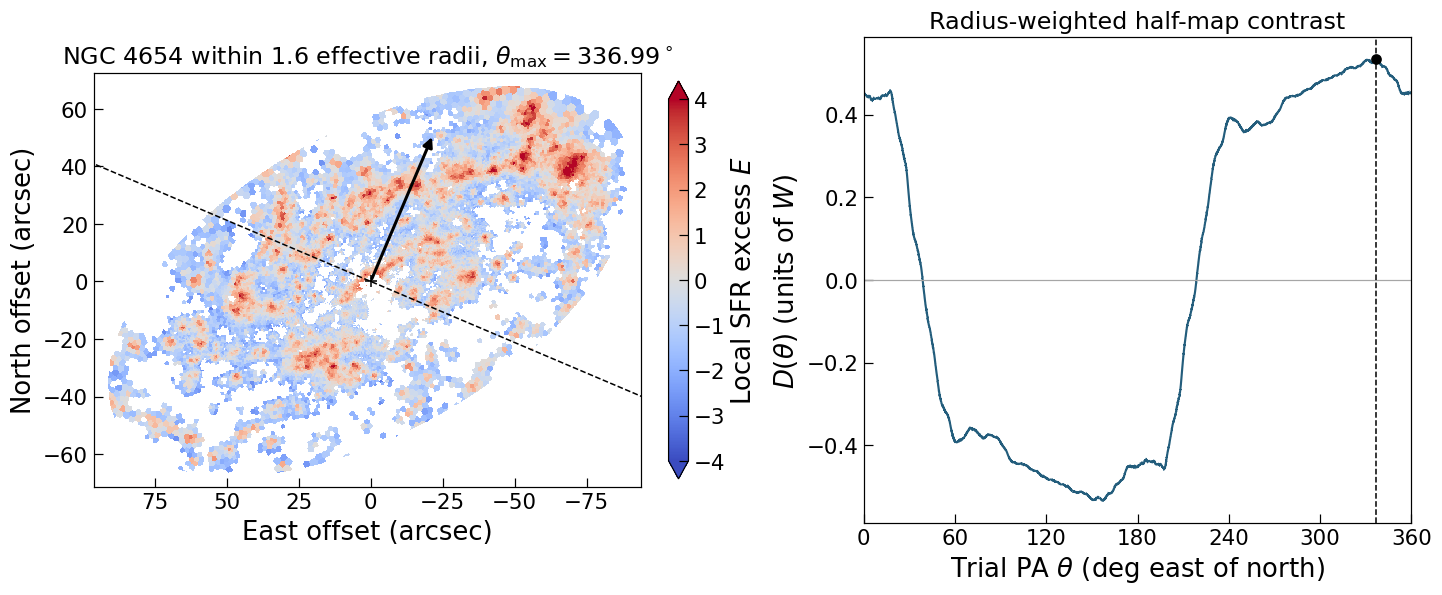

In [10]:
fig_radial_map, (ax_radial_map, ax_radial_curve) = plt.subplots(1, 2, figsize=(13, 5.3), layout='constrained')
mesh = ax_radial_map.pcolormesh(east, north, radial_spaxel_map, cmap='coolwarm', vmin=-4, vmax=4,
                         shading='flat', rasterized=True)
fig_radial_map.colorbar(mesh, ax=ax_radial_map, label=r'Local SFR excess $E$', extend='both', shrink=0.82)

radial_angle = np.deg2rad(radial_theta)
extent = np.hypot(radial_spaxels.east, radial_spaxels.north).max()
along_line = np.array([-2, 2]) * extent
ax_radial_map.plot(along_line * np.cos(radial_angle), -along_line * np.sin(radial_angle),
            'k--', lw=1, label='Dividing line')
ax_radial_map.annotate('', xy=0.55 * extent * np.array([np.sin(radial_angle), np.cos(radial_angle)]),
                xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', lw=2, color='black'))
ax_radial_map.plot(0, 0, 'k+', ms=8)
yy, xx = np.nonzero(radial_sf_mask)
margin = 5
ax_radial_map.set(aspect='equal', xlim=(east[yy, xx].max() + margin, east[yy, xx].min() - margin),
           ylim=(north[yy, xx].min() - margin, north[yy, xx].max() + margin),
           xlabel='East offset (arcsec)', ylabel='North offset (arcsec)',
           title=rf'NGC 4654 within {RADIAL_LIMIT_RE:g} effective radii, $\theta_{{\max}}={radial_theta:.2f}^\circ$')

curve = radial_cuts.D_W.where(radial_eligible).to_numpy()
plot_edges = np.r_[0, radial_cuts.start_deg, 360]
plot_values = np.r_[curve[-1], curve]
ax_radial_curve.stairs(plot_values, plot_edges, baseline=None, color='#235d7c', linewidth=1.4)
ax_radial_curve.axhline(0, color='0.65', linewidth=0.8)
ax_radial_curve.axvline(radial_theta, color='black', linestyle='--', linewidth=1)
ax_radial_curve.scatter(radial_theta, radial_contrast, color='black', zorder=3)
ax_radial_curve.set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
             xlabel=r'Trial PA $\theta$ (deg east of north)', ylabel=r'$D(\theta)$ (units of $W$)',
             title='Radius-weighted half-map contrast')
plt.show()

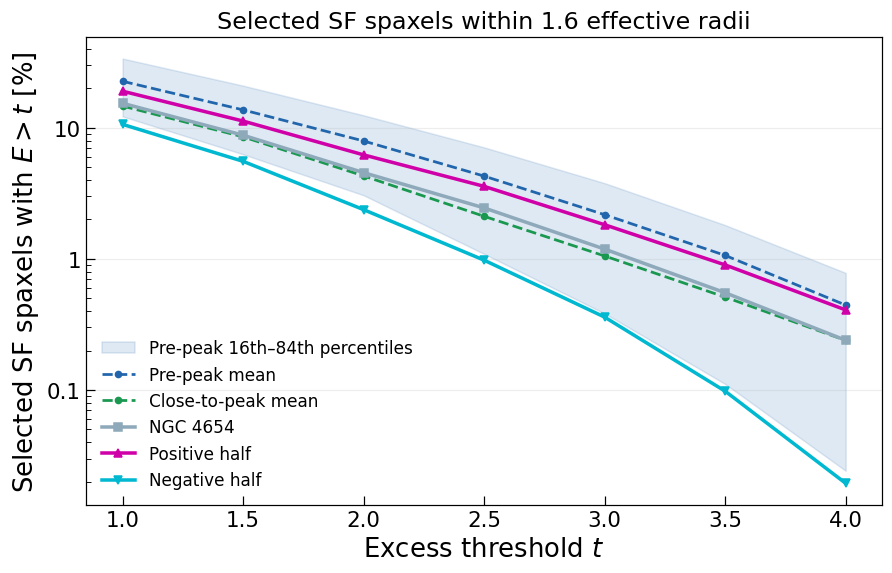

E threshold,Selected SF total,1.0,1.5,2.0,2.5,3.0,3.5,4.0
NGC4654,272907,42006,23984,12426,6687,3243,1507,654
Positive half,154512,29419,17409,9612,5529,2817,1391,631
Negative half,118395,12587,6575,2814,1158,426,116,23


In [11]:
radial_values_by_galaxy = {
    record.galaxy: excess_values[within_radius & (sf_group == group_id)]
    for group_id, record in excess_meta.iterrows()
}
radial_galaxy_tails = {
    gal: tail_counts(values) / values.size
    for gal, values in radial_values_by_galaxy.items() if values.size
}
radial_stage_tails = {
    stage: np.stack([radial_galaxy_tails[gal] for gal in excess_meta.loc[
        excess_meta.stage.eq(stage) & excess_meta.galaxy.isin(radial_galaxy_tails), 'galaxy']])
    for stage in (1, 2)
}
radial_stage_means = {stage: tails.mean(axis=0) for stage, tails in radial_stage_tails.items()}
radial_pre_bounds = np.quantile(radial_stage_tails[1], [0.16, 0.84], axis=0)

radial_region_values = {GALAXY: radial_values_by_galaxy[GALAXY], **radial_half_values}
radial_region_counts = {label: tail_counts(values) for label, values in radial_region_values.items()}
radial_region_fractions = {
    label: radial_region_counts[label] / values.size for label, values in radial_region_values.items()
}
assert np.allclose(radial_region_fractions[GALAXY], radial_galaxy_tails[GALAXY])

fig_radial_fraction, ax_radial_fraction = plt.subplots(figsize=(8.0, 5.1), layout='constrained')
ax_radial_fraction.fill_between(excess_thresholds, 100 * radial_pre_bounds[0], 100 * radial_pre_bounds[1],
    where=radial_pre_bounds[0] > 0, color=STAGE_COLORS[1], alpha=0.14,
    label='Pre-peak 16th–84th percentiles')
for stage in (1, 2):
    ax_radial_fraction.plot(excess_thresholds, 100 * radial_stage_means[stage], 'o--', lw=1.8, ms=4,
        color=STAGE_COLORS[stage], label=f'{STAGE_LABELS[stage]} mean')
region_colors = {
    GALAXY: GALAXY_COLORS[GALAXY],
    'Positive half': '#d000a8',
    'Negative half': '#00b9d0',
}
for (label, fraction), marker in zip(radial_region_fractions.items(), ('s', '^', 'v')):
    ax_radial_fraction.plot(excess_thresholds, 100 * fraction, marker=marker, ms=5, lw=2.3,
        color=region_colors[label], label='NGC 4654' if label == GALAXY else label)
ax_radial_fraction.set(xticks=excess_thresholds, xlabel=r'Excess threshold $t$',
    title=f'Selected SF spaxels within {RADIAL_LIMIT_RE:g} effective radii',
    ylabel='Selected SF spaxels with $E>t$ [%]')
ax_radial_fraction.set_yscale('log', nonpositive='mask')
ax_radial_fraction.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
ax_radial_fraction.grid(axis='y', alpha=0.22)
ax_radial_fraction.legend(loc='lower left', frameon=False, fontsize=11)
plt.show()

radial_support = pd.DataFrame(radial_region_counts, index=pd.Index(excess_thresholds, name='E threshold')).T
radial_support.insert(0, 'Selected SF total', [values.size for values in radial_region_values.values()])
display(radial_support)
